In [18]:
from pathlib import Path
import csv
import json
import random

import fiftyone.zoo as foz
import fiftyone as fo
from PIL import Image, ImageOps
import matplotlib.pyplot as plt

## Finding 100 image with open-images-v7 with seed 42

In [19]:
from pathlib import Path

# Run the notebook with the project folder as the working directory
PROJECT_ROOT = Path.cwd()
ROOT = PROJECT_ROOT / "data" / "openimages_v7"

print("Dataset folder:", ROOT)
fo.config.dataset_zoo_dir = str(ROOT / "zoo")

split = "train"
count = 100
SEED = 42
NUM_WORKERS = 1

dataset = foz.load_zoo_dataset(
    "open-images-v7",
    split=split,
    max_samples=count,
    shuffle=True,
    seed=SEED,
    label_types=[],
    num_workers=NUM_WORKERS,
    dataset_name=f"dsc4008-oi7-{split}-{count}-seed{SEED}-fixed",
)

print("Loaded images:", len(dataset))

Dataset folder: s:\DSC4008-image\data\openimages_v7
Necessary images already downloaded
Existing download of split 'train' is sufficient
Loading existing dataset 'dsc4008-oi7-train-100-seed42-fixed'. To reload from disk, either delete the existing dataset or provide a custom `dataset_name` to use
Loaded images: 100


In [20]:
# Disable automatic notebook display
session = fo.launch_app(dataset, auto=False)

# Open in a separate browser tab
session.open_tab()

print("App URL:", session.url)

Session launched. Run `session.show()` to open the App in a cell output.


<IPython.core.display.Javascript object>

App URL: http://localhost:5151/


## Get the image and Crop into 256 x 256

In [21]:
image_paths = sorted(Path(path) for path in dataset.values("filepath"))

PATCH_SIZE = 256

usable_paths = []
rejected = []

for path in image_paths:
    try:
        with Image.open(path) as image:
            image = ImageOps.exif_transpose(image)
            image.load()
            width, height = image.size

        if min(width, height) >= PATCH_SIZE:
            usable_paths.append(path)
        else:
            rejected.append((path.name, "Too small"))

    except OSError as error:
        rejected.append((path.name, str(error)))

print("Usable photographs:", len(usable_paths))
print("Rejected photographs:", len(rejected))

assert usable_paths, "No suitable images found."

Usable photographs: 100
Rejected photographs: 0


In [22]:
import numpy as np

rng = np.random.default_rng(SEED)

source_path = usable_paths[0]

with Image.open(source_path) as image:
    image = ImageOps.exif_transpose(image).convert("RGB")
    source = np.asarray(image, dtype=np.float32) / 255.0

height, width, channels = source.shape

# Random top-left position for the crop
top = int(rng.integers(0, height - PATCH_SIZE + 1))
left = int(rng.integers(0, width - PATCH_SIZE + 1))

clean = source[
    top : top + PATCH_SIZE,
    left : left + PATCH_SIZE,
].copy()

print("Source shape:", source.shape)
print("Clean patch shape:", clean.shape)
print("Pixel range:", clean.min(), clean.max())

Source shape: (683, 1024, 3)
Clean patch shape: (256, 256, 3)
Pixel range: 0.0 0.61960787


## Add Noise and Make "Noise and Clean Image Pair"

In [23]:
SIGMA = 25 / 255.0  # Noise strength on the [0, 1] intensity scale

noise = rng.normal(
    loc=0.0,
    scale=SIGMA,
    size=clean.shape,
).astype(np.float32)

noisy = clean + noise

print("Clean target:", clean.shape)
print("Noisy input:", noisy.shape)

Clean target: (256, 256, 3)
Noisy input: (256, 256, 3)


In [24]:
training_input = noisy
training_target = clean

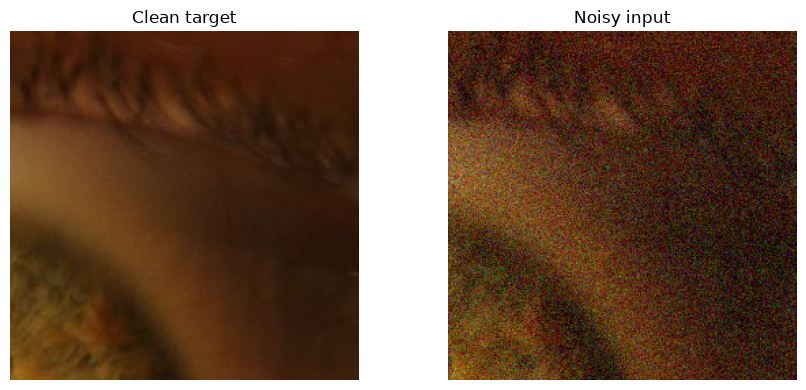

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(clean)
axes[0].set_title("Clean target")

axes[1].imshow(np.clip(noisy, 0, 1))
axes[1].set_title("Noisy input")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

### Original Image Comparsion

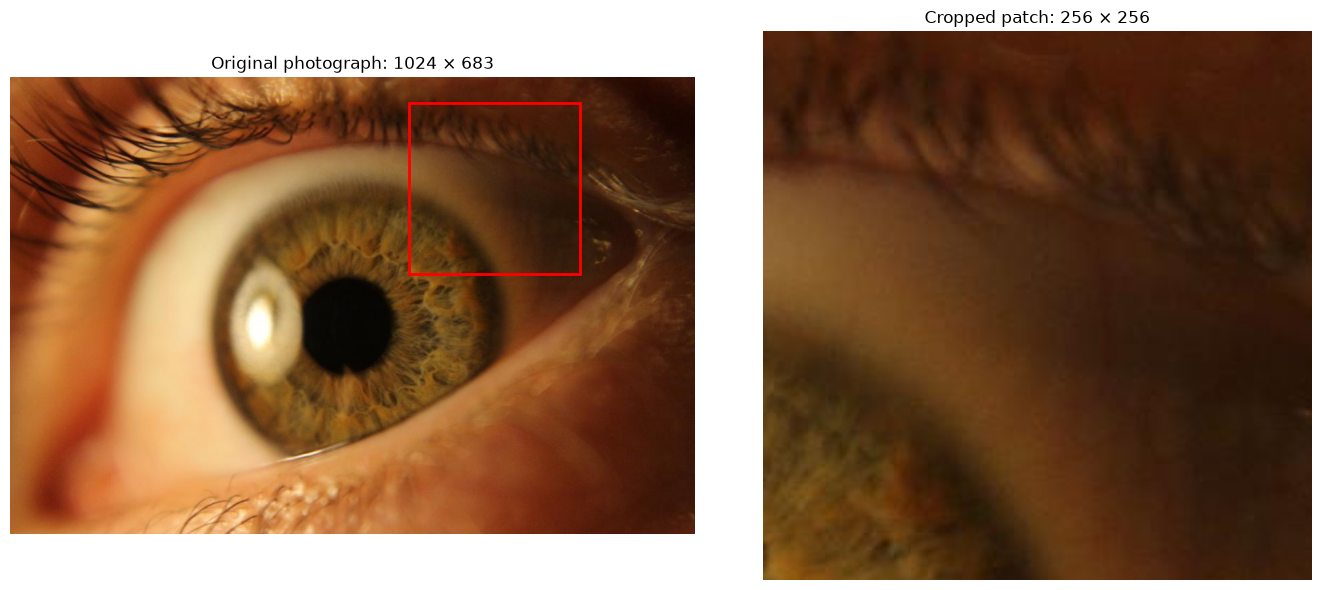

Original file: S:\DSC4008-image\data\openimages_v7\zoo\open-images-v7\train\data\00c013ada06af34c.jpg


In [26]:
# %%
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(source)
axes[0].set_title(
    f"Original photograph: {source.shape[1]} × {source.shape[0]}"
)

# Mark the area used for your crop
rectangle = plt.Rectangle(
    (left, top),
    PATCH_SIZE,
    PATCH_SIZE,
    edgecolor="red",
    facecolor="none",
    linewidth=2,
)
axes[0].add_patch(rectangle)

axes[1].imshow(clean)
axes[1].set_title(f"Cropped patch: {PATCH_SIZE} × {PATCH_SIZE}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Original file:", source_path)

In [27]:
assert clean.shape == noisy.shape
assert clean.dtype == np.float32
assert np.isfinite(noisy).all()

print("Actual noise standard deviation:", float((noisy - clean).std()))
print("Requested standard deviation:", SIGMA)

Actual noise standard deviation: 0.09831202775239944
Requested standard deviation: 0.09803921568627451


## Function for making traning pair

In [28]:
def make_training_pair(path, rng, patch_size=256, sigma=25 / 255):
    """Return a noisy input and its matching clean target."""

    with Image.open(path) as image:
        image = ImageOps.exif_transpose(image).convert("RGB")
        image = np.asarray(image, dtype=np.float32) / 255.0

    height, width, _ = image.shape

    if min(height, width) < patch_size:
        raise ValueError(f"Image is too small: {path}")

    top = int(rng.integers(0, height - patch_size + 1))
    left = int(rng.integers(0, width - patch_size + 1))

    clean = image[
        top:top + patch_size,
        left:left + patch_size,
    ].copy()

    noise = rng.normal(
        loc=0.0,
        scale=sigma,
        size=clean.shape,
    ).astype(np.float32)

    noisy = clean + noise

    return noisy, clean

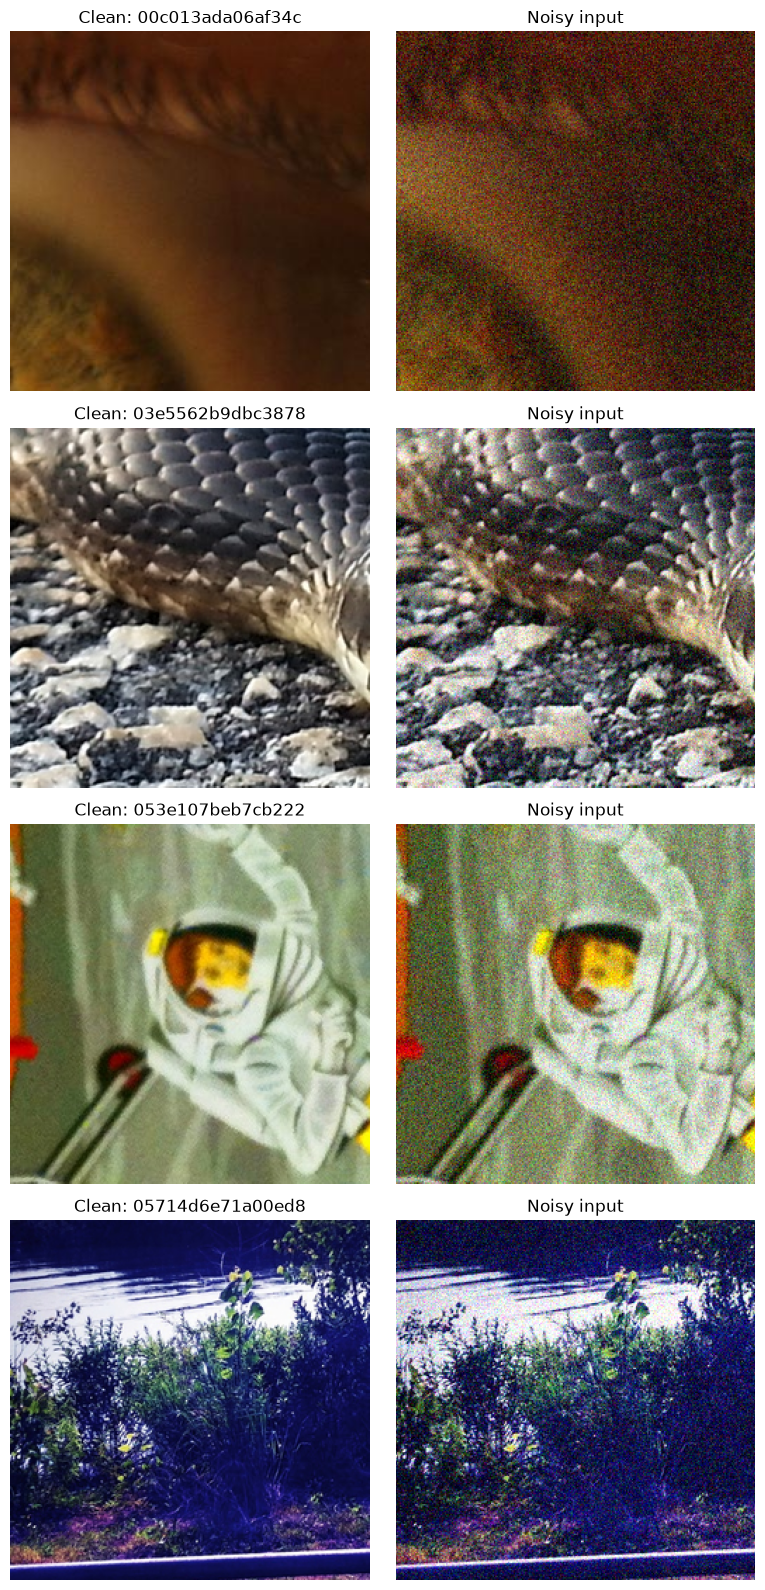

In [29]:
preview_rng = np.random.default_rng(SEED)
preview_paths = usable_paths[:4]

fig, axes = plt.subplots(
    len(preview_paths), 2,
    figsize=(8, 4 * len(preview_paths)),
    squeeze=False,
)

for row, path in enumerate(preview_paths):
    noisy_patch, clean_patch = make_training_pair(
        path,
        rng=preview_rng,
        patch_size=PATCH_SIZE,
        sigma=SIGMA,
    )

    axes[row, 0].imshow(clean_patch)
    axes[row, 0].set_title(f"Clean: {path.stem}")

    axes[row, 1].imshow(np.clip(noisy_patch, 0, 1))
    axes[row, 1].set_title("Noisy input")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [30]:
train_dataset = dataset

train_paths = sorted(
    Path(p) for p in train_dataset.values("filepath")
)

print("Training images:", len(train_paths))

Training images: 100


## Make Validation Dataset witn 20 image

In [31]:
validation_dataset = foz.load_zoo_dataset(
    "open-images-v7",
    split="validation",
    max_samples=20,
    shuffle=True,
    seed=SEED,
    label_types=[],
    num_workers=NUM_WORKERS,
    dataset_name=f"dsc4008-oi7-validation-20-seed{SEED}-fixed",
)

validation_paths = sorted(
    Path(p) for p in validation_dataset.values("filepath")
)

print("Validation images:", len(validation_paths))

Necessary images already downloaded
Existing download of split 'validation' is sufficient
Loading existing dataset 'dsc4008-oi7-validation-20-seed42-fixed'. To reload from disk, either delete the existing dataset or provide a custom `dataset_name` to use
Validation images: 20


In [32]:
# Disable automatic notebook display
session = fo.launch_app(validation_dataset, auto=False)

# Open in a separate browser tab
session.open_tab()

print("App URL:", session.url)

Session launched. Run `session.show()` to open the App in a cell output.


<IPython.core.display.Javascript object>

App URL: http://localhost:5151/


In [33]:
def find_usable_images(paths, patch_size):
    usable = []

    for path in paths:
        try:
            with Image.open(path) as image:
                image = ImageOps.exif_transpose(image)
                image.load()

                if min(image.size) >= patch_size:
                    usable.append(path)

        except OSError as error:
            print("Could not read:", path.name, error)

    return usable


train_paths = find_usable_images(train_paths, PATCH_SIZE)
validation_paths = find_usable_images(validation_paths, PATCH_SIZE)

assert train_paths, "No suitable training images."
assert validation_paths, "No suitable validation images."

print("Usable training images:", len(train_paths))
print("Usable validation images:", len(validation_paths))

Usable training images: 100
Usable validation images: 20


In [ ]:
validation_rng = np.random.default_rng(SEED)

validation_pairs = [
    make_training_pair(
        path,
        rng=validation_rng,
        patch_size=PATCH_SIZE,
        sigma=SIGMA,
    )
    for path in validation_paths
]

print("Fixed validation pairs:", len(validation_pairs))

Fixed validation pairs: 20


The `show_confidence` App config option has been removed and no longer has any effect. Label attribute visibility is controlled per attribute in the App's sidebar
The `show_index` App config option has been removed and no longer has any effect. Label attribute visibility is controlled per attribute in the App's sidebar
The `show_label` App config option has been removed and no longer has any effect. Label attribute visibility is controlled per attribute in the App's sidebar
The `show_confidence` App config option has been removed and no longer has any effect. Label attribute visibility is controlled per attribute in the App's sidebar
The `show_index` App config option has been removed and no longer has any effect. Label attribute visibility is controlled per attribute in the App's sidebar
The `show_label` App config option has been removed and no longer has any effect. Label attribute visibility is controlled per attribute in the App's sidebar
